# NYC facade typologies: clustering the buildings of the facade inspection programme

**Team:** Amelia, Jerome, Kazuko, Sahil
**Course:** AI Methods I – Day 3: Unsupervised learning (IAAC MaAI 2026/27)

## 0. Introduction and problem definition

On Day 2 we predicted which facades would be found **UNSAFE** in New York City's facade inspection programme (FISP, Local Law 11).
The model told us *how risky* a building is, but not *what kind of building* it is. Today we look for **facade typologies**:
groups of buildings whose facades are built in the same way.

**Use case.** A facade consultant or the NYC Department of Buildings (DOB) plans the next inspection cycle.
Facades of the same type fail in the same way (terra cotta cracks, brick spalls, curtain-wall sealants age, concrete frames lose their cover),
so knowing **which typology a building belongs to** helps to:
- send the right **specialist** (a terra cotta expert is not a curtain-wall expert),
- plan **typical repairs and budgets** per typology,
- see **which typologies are UNSAFE more often** and deserve attention first.

**What makes a group useful:** we can **name** it with words a facade engineer uses ("brick cavity wall", "curtain wall"),
and it shows a **different UNSAFE rate**, so someone can act on it.

**Unit of analysis: one building** (identified by its `BIN`, Building Identification Number).
Our Day 2 table had one row per **filing** (one inspection report of one building in one 5-year cycle).
The same building appears up to 5 times (cycles 6–10), so we **aggregate the filings per building** (section 0.2).

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
DATASET_DIR = Path("..") / "dataset"   # the clustered dataset we publish
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(exist_ok=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

C:\Users\schei\AppData\Local\Temp\claude\C--Users-schei-Desktop-private-2027-jan-feb-trip-plan\ec4b1f6d-5d2c-4f48-b64d-4c900fa9f4cd\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 0.1 Load and clean the data (same steps as Day 2)

We use the same dataset as on Day 1/2: **DOB NOW: Safety – Facades Compliance Filings**
([NYC Open Data, xubg-57si](https://data.cityofnewyork.us/d/xubg-57si)). The cell below downloads it (once) and repeats,
in one place, the cleaning of our Day 2 notebook `data_cleaning_and_EDA.ipynb` (sections 1.1–1.7):

| Step | What |
|---|---|
| Column names | `UPPER_SNAKE_CASE` |
| Duplicates | exact copies removed, then one row per filing number `TR6_NO` |
| Dropped columns | free text, inspector and **owner contact details (personal data)**, `CONTROL_NO`, `SUBMITTED_ON`, `CURRENT_STATUS` |
| Not real inspections | `NO REPORT FILED` placeholders removed |
| Text | capitals, single spaces |
| Types | dates parsed, `CYCLE` as integer, placeholder `BIN`s (`1000000`…) and `BIN`s in the wrong borough set to missing |

In [2]:
RAW_PATH = DATA_DIR / "facades_compliance_filings_raw.csv"
URL = "https://data.cityofnewyork.us/api/views/xubg-57si/rows.csv?accessType=DOWNLOAD"
if not RAW_PATH.exists():
    pd.read_csv(URL, low_memory=False).to_csv(RAW_PATH, index=False)
raw = pd.read_csv(RAW_PATH, low_memory=False)
print(f"Raw data: {raw.shape[0]:,} rows, {raw.shape[1]} columns")

filings = raw.copy()
filings.columns = (
    filings.columns.str.replace("(s)", "S", regex=False).str.upper()
    .str.replace(r"[^A-Z0-9]+", "_", regex=True).str.strip("_")
)
filings = filings.drop_duplicates().drop_duplicates(subset="TR6_NO", keep="first")
filings = filings.drop(columns=[
    "COMMENTS", "EXTERIOR_WALL_TYPE_OTHER_DESCRIPTION", "EXTERIOR_WALL_MATERIAL_OTHER_DESCRIPTION",
    "QEWI_NAME", "QEWI_BUS_NAME", "QEWI_BUS_STREET_NAME", "QEWI_CITY", "QEWI_STATE", "QEWI_ZIP", "QEWI_NYS_LIC_NO",
    "OWNER_NAME", "OWNER_BUS_NAME", "OWNER_BUS_STREET_NAME", "OWNER_CITY", "OWNER_STATE", "OWNER_ZIP",
    "CONTROL_NO", "SUBMITTED_ON", "CURRENT_STATUS",
])
filings = filings[filings["FILING_STATUS"].str.upper() != "NO REPORT FILED"].reset_index(drop=True)

for col in filings.select_dtypes(include=["object", "string"]).columns:
    filings[col] = filings[col].str.upper().str.replace(r"\s+", " ", regex=True).str.strip()

filings["FILING_DATE"] = pd.to_datetime(filings["FILING_DATE"], format="%m/%d/%Y", errors="coerce")
filings["CYCLE"] = filings["CYCLE"].astype("Int64")
filings["BIN"] = filings["BIN"].astype("Int64")
borough_number = {"MANHATTAN": "1", "BRONX": "2", "BROOKLYN": "3", "QUEENS": "4", "STATEN ISLAND": "5"}
bin_text = filings["BIN"].astype("string")
bad_bin = bin_text.str.fullmatch(r"\d000000", na=False) | (
    bin_text.notna() & (bin_text.str[0] != filings["BOROUGH"].map(borough_number))
)
filings.loc[bad_bin, "BIN"] = pd.NA
penalty_columns = ["LATE_FILING_AMT", "FAILURE_TO_FILE_AMT", "FAILURE_TO_CORRECT_AMT"]
filings["TOTAL_PENALTY_AMT"] = filings[penalty_columns].sum(axis=1, min_count=1)

print(f"Clean filings: {len(filings):,}")
filings["FILING_TYPE"].value_counts()

Raw data: 87,556 rows, 40 columns


Clean filings: 67,732


FILING_TYPE
INITIAL       54108
AMENDED        9400
SUBSEQUENT     4224
Name: count, dtype: int64

The numbers match our Day 2 cleaning (67,7xx real reports; small differences come from the data being updated since 23 October).

### 0.2 From filings to buildings

We keep only the **INITIAL** filings (the first report of a building in a cycle; Day 2 showed that amended and subsequent
filings only exist *after* a result) that have a valid `BIN` and a description of the facade (`EXTERIOR_WALL_MATERIALS`).

In [3]:
initial = filings[
    (filings["FILING_TYPE"] == "INITIAL")
    & filings["BIN"].notna()
    & filings["EXTERIOR_WALL_MATERIALS"].notna()
].copy()
print(f"{len(initial):,} initial filings with a facade description, for {initial['BIN'].nunique():,} buildings")

reports_per_building = initial.groupby("BIN").size()
reports_per_building.value_counts().sort_index().rename("buildings").to_frame().T

52,245 initial filings with a facade description, for 15,747 buildings


,1,2,3,4,5,6,7,8,9,10,11,12,14,16,21
buildings,2021,1959,2519,7741,1406,50,11,25,3,4,2,2,2,1,1


Most buildings have 4 reports (one per cycle 6–9), but some have only 1 (new in the programme, or missing years).

### 0.3 New features: what the facade is made of

Each report lists the **wall types** and the **materials** of the facade, as text with several values: `"MASONRY; TERRA COTTA"`.
There are 18 wall types and 12 materials, some of them very rare (`BROWNSTONE`: 95 reports, `GFRC`: 172), so we **group them
into families** that a facade engineer would recognise:

| New column | Grouped from | Meaning |
|---|---|---|
| `MAT_BRICK` | MASONRY | brick (the material) |
| `MAT_TERRA_COTTA` | TERRA COTTA | glazed terra cotta (ornament, cladding) |
| `MAT_STONE` | NATURAL STONE, CAST STONE | stone (natural or cast) |
| `MAT_CONCRETE` | CONCRETE, GFRC | concrete, glass-fibre reinforced concrete |
| `MAT_STUCCO_EIFS` | STUCCO/EIFS | render, external insulation |
| `MAT_GLASS` | GLASS | glass |
| `MAT_METAL` | METAL, SHEET METAL, CAST IRON | metal |
| `WALL_MASONRY_LOAD_BEARING` | BRICK MASONRY, MASONRY LOAD-BEARING WALL, BROWNSTONE, STONE MARBLE, STONE LIMESTONE | solid masonry walls that carry the building |
| `WALL_MASONRY_CAVITY` | MASONRY CAVITY WALL, CONCRETE BLOCK MASONRY | masonry veneer with an air gap, on a frame or block back-up |
| `WALL_STEEL_FRAME` | STEEL FRAME | steel skeleton |
| `WALL_CONCRETE_FRAME` | CONCRETE FRAME, CONCRETE | concrete skeleton or concrete walls |
| `WALL_CURTAIN_WALL` | CURTAIN WALL, METAL & GLASS, GLASS, METAL SIDING/PANELS | non-structural glass or metal skin |
| `WALL_TERRA_COTTA_CLAD` | TERRA COTTA (wall type) | terra cotta cladding |

`OTHER` (used in about a third of reports) is kept **aside** in `MAT_OTHER` and `WALL_OTHER`: it says "something not in the list",
not what the facade is.

For each building we then take the **share of its reports** that mention each family (a number between 0 and 1).
A building described as brick in all 4 cycles gets `MAT_BRICK = 1.0`; one described as brick in 2 out of 4 gets 0.5.
This smooths out inspectors who described the same facade differently from one cycle to the next.

In [4]:
MATERIAL_FAMILIES = {
    "MAT_BRICK": ["MASONRY"],
    "MAT_TERRA_COTTA": ["TERRA COTTA"],
    "MAT_STONE": ["NATURAL STONE", "CAST STONE"],
    "MAT_CONCRETE": ["CONCRETE", "GFRC"],
    "MAT_STUCCO_EIFS": ["STUCCO/EIFS"],
    "MAT_GLASS": ["GLASS"],
    "MAT_METAL": ["METAL", "SHEET METAL", "CAST IRON"],
}
WALL_FAMILIES = {
    "WALL_MASONRY_LOAD_BEARING": ["BRICK MASONRY", "MASONRY LOAD-BEARING WALL", "BROWNSTONE", "STONE MARBLE", "STONE LIMESTONE"],
    "WALL_MASONRY_CAVITY": ["MASONRY CAVITY WALL", "CONCRETE BLOCK MASONRY"],
    "WALL_STEEL_FRAME": ["STEEL FRAME"],
    "WALL_CONCRETE_FRAME": ["CONCRETE FRAME", "CONCRETE"],
    "WALL_CURTAIN_WALL": ["CURTAIN WALL", "METAL & GLASS", "GLASS", "METAL SIDING/PANELS"],
    "WALL_TERRA_COTTA_CLAD": ["TERRA COTTA"],
}

material_dummies = initial["EXTERIOR_WALL_MATERIALS"].str.get_dummies(sep="; ")
wall_dummies = initial["EXTERIOR_WALL_TYPES"].str.get_dummies(sep="; ")
for new_col, values in MATERIAL_FAMILIES.items():
    initial[new_col] = material_dummies.reindex(columns=values, fill_value=0).max(axis=1)
for new_col, values in WALL_FAMILIES.items():
    initial[new_col] = wall_dummies.reindex(columns=values, fill_value=0).max(axis=1)
initial["MAT_OTHER"] = material_dummies.get("OTHER", 0)
initial["WALL_OTHER"] = wall_dummies.get("OTHER", 0)
initial["N_MATERIALS"] = material_dummies.drop(columns="OTHER", errors="ignore").sum(axis=1)

FEATURES = list(MATERIAL_FAMILIES) + list(WALL_FAMILIES)
print(f"{len(FEATURES)} facade features: {FEATURES}")

13 facade features: ['MAT_BRICK', 'MAT_TERRA_COTTA', 'MAT_STONE', 'MAT_CONCRETE', 'MAT_STUCCO_EIFS', 'MAT_GLASS', 'MAT_METAL', 'WALL_MASONRY_LOAD_BEARING', 'WALL_MASONRY_CAVITY', 'WALL_STEEL_FRAME', 'WALL_CONCRETE_FRAME', 'WALL_CURTAIN_WALL', 'WALL_TERRA_COTTA_CLAD']


Now one row per building. Besides the facade shares, we compute columns we will **not** cluster on, but use to **interpret** the groups:
location, how long the building has been in the programme, and its **inspection history** (how often it was UNSAFE).
For the address and the latest status we use the building's **most recent** report.

In [5]:
initial = initial.sort_values(["BIN", "CYCLE", "FILING_DATE"])
grouped = initial.groupby("BIN")
latest = grouped.last()

buildings = pd.DataFrame({
    "BOROUGH": latest["BOROUGH"],
    "BLOCK": latest["BLOCK"].replace(99999, np.nan).astype("Int64"),
    "LOT": latest["LOT"].astype("Int64"),
    "HOUSE_NO": latest["HOUSE_NO"],
    "STREET_NAME": latest["STREET_NAME"],
    "FIRST_CYCLE": grouped["CYCLE"].min(),
    "LAST_CYCLE": grouped["CYCLE"].max(),
    "N_REPORTS": grouped.size(),
    "FIRST_FILING_YEAR": grouped["FILING_DATE"].min().dt.year.astype("Int64"),
    "LAST_FILING_YEAR": grouped["FILING_DATE"].max().dt.year.astype("Int64"),
    "LATEST_STATUS": latest["FILING_STATUS"],
    "N_UNSAFE": grouped["FILING_STATUS"].apply(lambda s: (s == "UNSAFE").sum()),
    "N_SWARMP": grouped["FILING_STATUS"].apply(lambda s: (s == "SWARMP").sum()),
    "TOTAL_PENALTY_AMT": grouped["TOTAL_PENALTY_AMT"].sum(min_count=1),
    "EXTERIOR_WALL_TYPES_LATEST": latest["EXTERIOR_WALL_TYPES"],
    "EXTERIOR_WALL_MATERIALS_LATEST": latest["EXTERIOR_WALL_MATERIALS"],
})
buildings["SHARE_UNSAFE"] = buildings["N_UNSAFE"] / buildings["N_REPORTS"]
buildings["EVER_UNSAFE"] = (buildings["N_UNSAFE"] > 0).astype(int)
buildings = buildings.join(grouped[FEATURES + ["MAT_OTHER", "WALL_OTHER", "N_MATERIALS"]].mean())
buildings = buildings.reset_index()

print(f"{len(buildings):,} buildings, {buildings.shape[1]} columns, duplicated BIN: {buildings['BIN'].duplicated().sum()}")
buildings.head()

15,747 buildings, 35 columns, duplicated BIN: 0


,BIN,BOROUGH,BLOCK,LOT,HOUSE_NO,STREET_NAME,FIRST_CYCLE,LAST_CYCLE,N_REPORTS,FIRST_FILING_YEAR,LAST_FILING_YEAR,LATEST_STATUS,N_UNSAFE,N_SWARMP,TOTAL_PENALTY_AMT,EXTERIOR_WALL_TYPES_LATEST,EXTERIOR_WALL_MATERIALS_LATEST,SHARE_UNSAFE,EVER_UNSAFE,MAT_BRICK,MAT_TERRA_COTTA,MAT_STONE,MAT_CONCRETE,MAT_STUCCO_EIFS,MAT_GLASS,MAT_METAL,WALL_MASONRY_LOAD_BEARING,WALL_MASONRY_CAVITY,WALL_STEEL_FRAME,WALL_CONCRETE_FRAME,WALL_CURTAIN_WALL,WALL_TERRA_COTTA_CLAD,MAT_OTHER,WALL_OTHER,N_MATERIALS
0,1000005,MANHATTAN,4,7501,1,NEW YORK PLAZA,6,9,4,2006,2022,SWARMP,0,4,0.0,CURTAIN WALL; STEEL FRAME,GLASS; OTHER,0.0,0,0.00,0.75,0.0,0.0,0.0,1.00,0.0,0.0,0.00,0.25,0.0,1.00,0.75,1.00,0.75,1.75
1,1000006,MANHATTAN,5,7501,117,BROAD STREET,6,9,4,2006,2022,UNSAFE,2,0,80200.0,OTHER; CURTAIN WALL; MASONRY CAVITY WALL,MASONRY; GLASS; OTHER,0.5,1,0.25,0.00,0.0,0.0,0.0,0.75,0.0,0.0,0.25,0.00,0.0,0.75,0.00,1.00,1.00,1.00
2,1000007,MANHATTAN,5,10,113,BROAD STREET,6,10,5,2009,2026,SAFE,1,2,256250.0,MASONRY CAVITY WALL; STEEL FRAME; CURTAIN WALL,MASONRY; METAL; GLASS; STUCCO/EIFS; NATURAL STONE,0.2,1,1.00,0.00,0.2,0.2,0.2,0.20,0.2,0.6,0.20,0.40,0.0,0.40,0.00,0.00,0.20,2.00
3,1000016,MANHATTAN,8,44,102,BROAD STREET,6,9,4,2007,2022,SAFE,2,0,151000.0,MASONRY LOAD-BEARING WALL,OTHER; MASONRY,0.5,1,1.00,0.00,0.0,0.0,0.0,0.00,0.0,1.0,0.00,0.00,0.0,0.00,0.00,1.00,0.75,1.00
4,1000018,MANHATTAN,9,1,1,STATE STREET PLAZA,6,9,4,2007,2023,SWARMP,0,3,83400.0,CURTAIN WALL; STEEL FRAME,GLASS; METAL; MASONRY,0.0,0,0.25,0.00,0.0,0.0,0.0,1.00,1.0,0.0,0.00,0.25,0.0,1.00,0.00,0.75,0.75,2.25


In [6]:
# Quick check of the new table
buildings[FEATURES + ["N_REPORTS", "SHARE_UNSAFE", "TOTAL_PENALTY_AMT"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MAT_BRICK,15747.0,0.80,0.34,0.0,0.60,1.00,1.00,1.0
MAT_TERRA_COTTA,15747.0,0.14,0.31,0.0,0.00,0.00,0.00,1.0
MAT_STONE,15747.0,0.14,0.26,0.0,0.00,0.00,0.25,1.0
MAT_CONCRETE,15747.0,0.09,0.23,0.0,0.00,0.00,0.00,1.0
MAT_STUCCO_EIFS,15747.0,0.09,0.25,0.0,0.00,0.00,0.00,1.0
MAT_GLASS,15747.0,0.07,0.24,0.0,0.00,0.00,0.00,1.0
MAT_METAL,15747.0,0.09,0.25,0.0,0.00,0.00,0.00,1.0
WALL_MASONRY_LOAD_BEARING,15747.0,0.63,0.38,0.0,0.33,0.75,1.00,1.0
WALL_MASONRY_CAVITY,15747.0,0.14,0.27,0.0,0.00,0.00,0.25,1.0
WALL_STEEL_FRAME,15747.0,0.06,0.16,0.0,0.00,0.00,0.00,1.0


- **80%** of buildings have brick in their facade and **63%** load-bearing masonry walls: New York's tall-building stock is mostly masonry.
- The other families are each present in 6–14% of buildings: these are the minorities the clustering should find.
- On average a building was UNSAFE in about 23% of its reports.
- `N_REPORTS` is usually 1–5 (one per cycle), but a few `BIN`s have more: one BIN can cover a complex with several facade filings per cycle.
- `TOTAL_PENALTY_AMT` is very skewed (a few buildings have millions of dollars of fines). It is only kept for interpretation.

## 1. Features and preprocessing

**Clustered on (13 features):** the 7 material families and the 6 wall-type families. Our question is "which facades are built the
same way?", so **only the construction** defines "similar".

**Kept aside for interpretation:** `BOROUGH`, the inspection history (`SHARE_UNSAFE`, `EVER_UNSAFE`, `LATEST_STATUS`, penalties),
the years in the programme, and `MAT_OTHER` / `WALL_OTHER`. If we clustered on the UNSAFE history, we would get "risky / not risky"
groups again (that was Day 2). Keeping it aside lets us **test** whether typologies differ in risk.

**Scaling: none.** All 13 features are **shares between 0 and 1, in the same unit**. A `StandardScaler` would divide every column by its
standard deviation, so rare families (glass, curtain walls: few buildings, small spread) would get a much bigger weight than brick.
Without scaling, "1 on glass" and "1 on brick" count the same. (This is the same reasoning as the class example, where the 24 hourly
columns shared a unit.) There are no skewed or categorical columns among the features, so no log transform or one-hot encoding is needed.

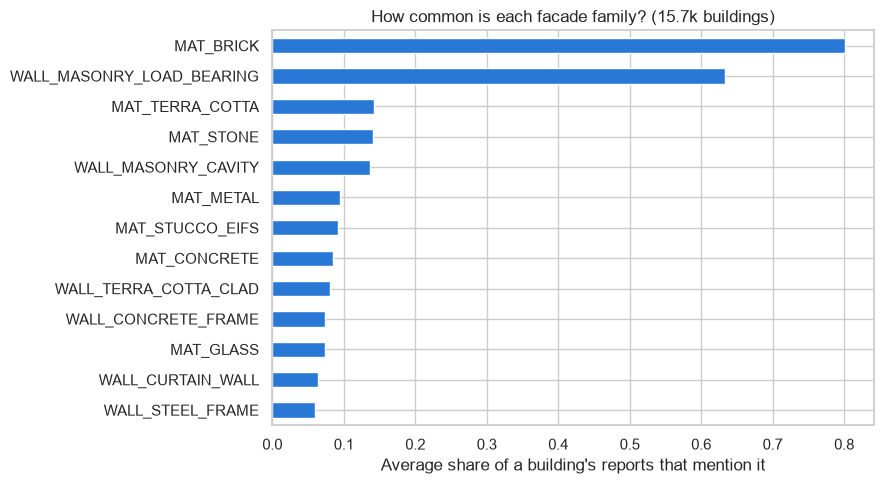

In [7]:
X = buildings[FEATURES].to_numpy()

fig, ax = plt.subplots(figsize=(9, 5))
shares = buildings[FEATURES].mean().sort_values()
shares.plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("Average share of a building's reports that mention it")
ax.set_title("How common is each facade family? (15.7k buildings)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_facade_families.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Dimensionality reduction

### 2.1 PCA

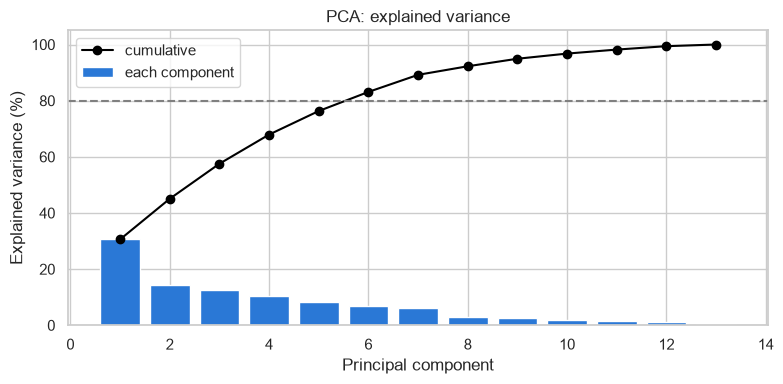

Explained variance (%): [30.6 14.5 12.5 10.4  8.4  6.8  6.1  3.1  2.7  1.8  1.4  1.2  0.6]
Components for 80%: 6


In [8]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(explained) + 1), explained * 100, color="#2a78d6", label="each component")
ax.plot(range(1, len(explained) + 1), np.cumsum(explained) * 100, "o-", color="black", label="cumulative")
ax.axhline(80, color="grey", linestyle="--")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_title("PCA: explained variance")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Explained variance (%):", (explained * 100).round(1))
print(f"Components for 80%: {np.argmax(np.cumsum(explained) >= 0.8) + 1}")

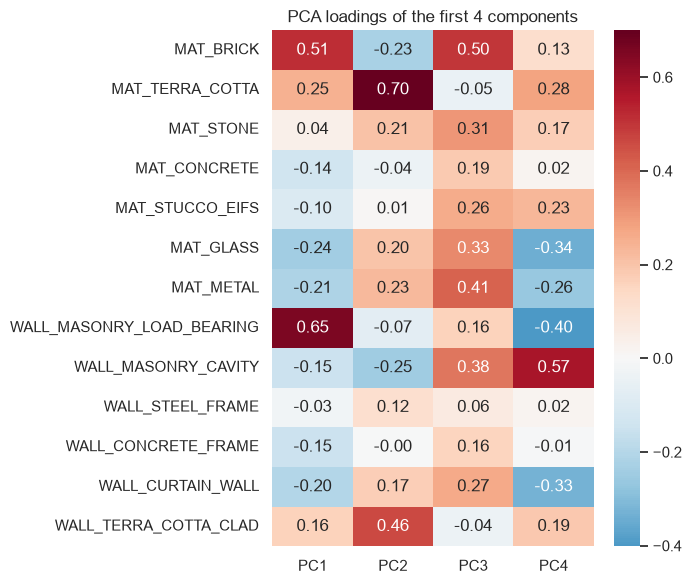

In [9]:
loadings = pd.DataFrame(pca.components_[:4].T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("PCA loadings of the first 4 components")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_pca_loadings.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the PCA.** No single component dominates: PC1 explains 31%, PC2 15%, PC3 13%, and **6 components** are needed for 80%.
The facades really vary in several independent directions.

- **PC1 (31%) – traditional masonry vs. modern skin.** High for load-bearing masonry (+0.65) and brick (+0.51); low for glass, metal,
  curtain wall, concrete. Left = modern framed buildings, right = traditional brick buildings.
- **PC2 (15%) – terra cotta.** Almost only terra cotta (material +0.70, cladding +0.46). It separates the ornamented buildings.
- **PC3 (13%) – "many materials".** Positive for nearly everything (metal, cavity wall, glass, stone, stucco): buildings whose reports
  list many materials at once, against plain brick-only facades.
- **PC4 (10%) – cavity wall vs. curtain wall / load-bearing.** Separates brick veneer on a back-up wall from the other systems.

So the data has about **4–6 real dimensions**, which already suggests a handful of typologies.

In [10]:
pca_coordinates = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

### 2.2 t-SNE and UMAP

Both draw the buildings in 2D so that buildings with similar facades are neighbours. We compute both and keep the coordinates.
Many buildings have **exactly the same** features (for example "brick, load-bearing" in every cycle), so they sit on top of each other.
For UMAP this was a real problem: without help it drew hundreds of isolated specks of identical buildings. We add a tiny random
jitter (standard deviation 0.02, on features that go from 0 to 1) **only for the UMAP map**; the clustering uses the exact values.

C:\Users\schei\AppData\Local\Temp\claude\C--Users-schei-Desktop-private-2027-jan-feb-trip-plan\ec4b1f6d-5d2c-4f48-b64d-4c900fa9f4cd\scratchpad\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


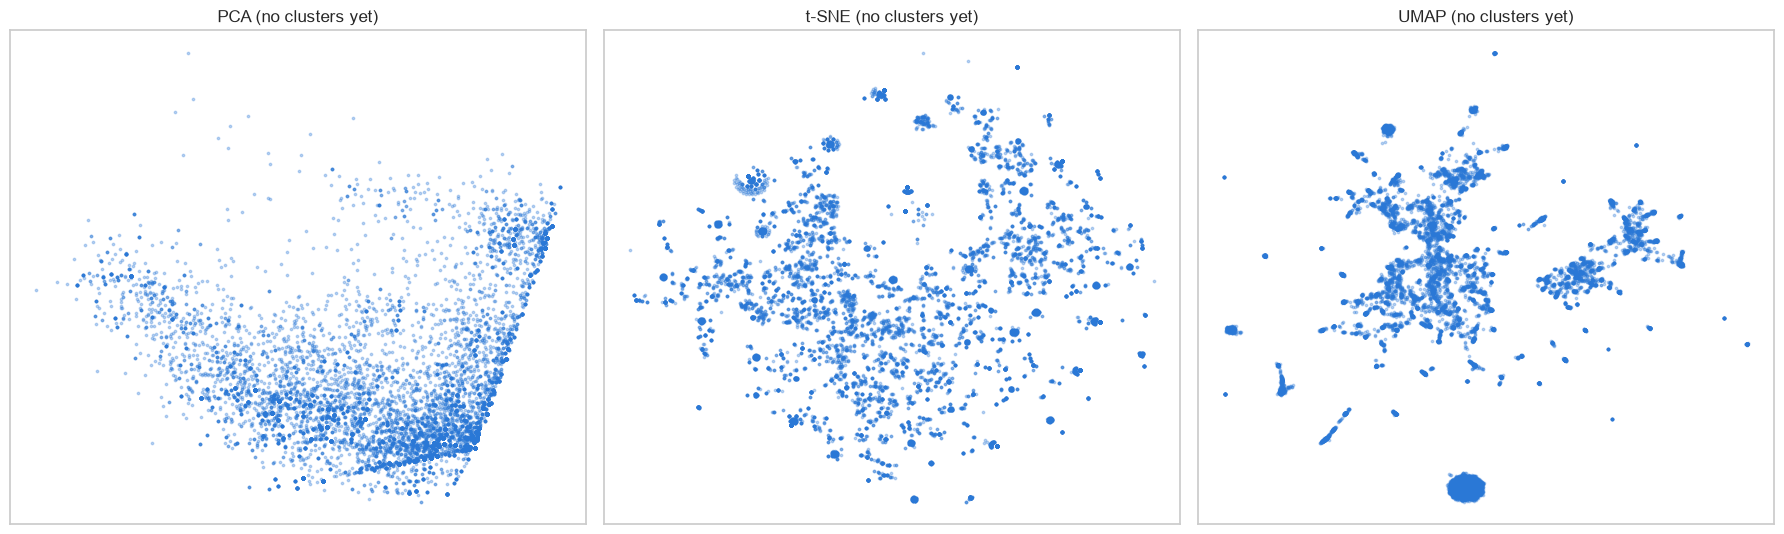

In [11]:
tsne_coordinates = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X)
# UMAP struggles with thousands of identical rows (it breaks them into isolated specks), so it gets a tiny jitter (sd 0.02)
X_jitter = X + np.random.default_rng(RANDOM_STATE).normal(0, 0.02, X.shape)
umap_coordinates = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X_jitter)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, coords, title in zip(axes, [pca_coordinates, tsne_coordinates, umap_coordinates], ["PCA", "t-SNE", "UMAP"]):
    ax.scatter(coords[:, 0], coords[:, 1], s=3, alpha=0.3, c="#2a78d6")
    ax.set_title(f"{title} (no clusters yet)")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(FIG_DIR / "04_maps_before_clustering.png", dpi=150, bbox_inches="tight")
plt.show()

**What the maps show.** The PCA map is a **V shape**: one arm goes towards terra cotta (top right), the other towards glass and metal
(left), with the large mass of plain brick buildings at the bottom of the V. t-SNE and UMAP show many **small dense knots**
(buildings with identical descriptions) grouped into a few regions; the big round blob on the UMAP map is thousands of buildings
described as "brick, load-bearing" and nothing else. Remember: on t-SNE and UMAP the sizes of the groups and the
distances between them mean nothing; only "who is next to whom" does.

## 3. Clustering

### 3.1 K-Means: choosing k

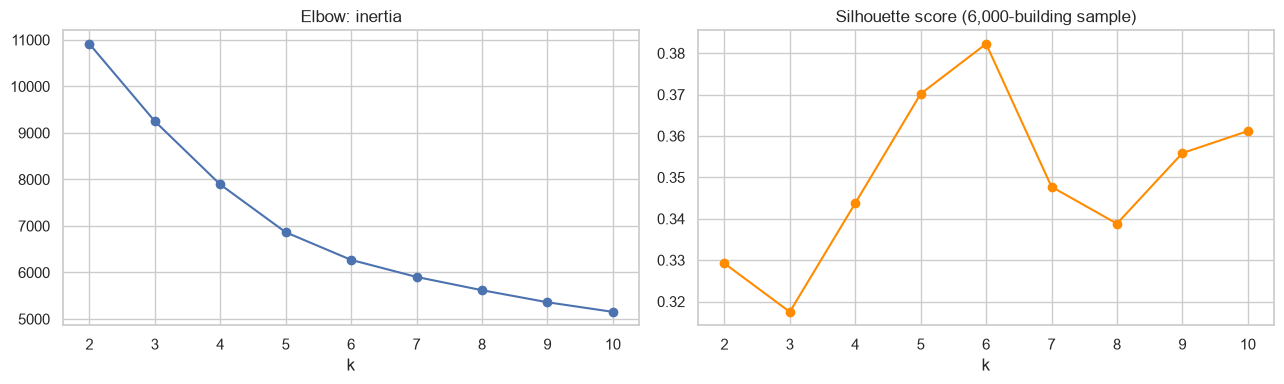

k,2,3,4,5,6,7,8,9,10
inertia,10914.000,9251.000,7891.000,6865.00,6271.000,5904.000,5619.000,5360.000,5153.000
silhouette,0.329,0.317,0.344,0.37,0.382,0.348,0.339,0.356,0.361


In [12]:
k_values = range(2, 11)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_, sample_size=6000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, "o-")
axes[0].set_title("Elbow: inertia")
axes[0].set_xlabel("k")
axes[1].plot(list(k_values), silhouettes, "o-", color="darkorange")
axes[1].set_title("Silhouette score (6,000-building sample)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_choice_of_k.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias), "silhouette": np.round(silhouettes, 3)}).set_index("k").T

**Choosing k.** The elbow curve bends slowly, with no sharp elbow. The silhouette, however, has a **clear peak at k = 6 (0.38)**,
higher than all its neighbours (0.37 at k = 5, 0.35 at k = 7). A silhouette of 0.38 is moderate: the groups are real but touch each
other. k = 6 also gives groups we can name (section 5), so we choose **k = 6**.

In [13]:
K = 6
kmeans_pipeline = Pipeline([("kmeans", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE))])
kmeans_pipeline.fit(buildings[FEATURES])
labels_kmeans = kmeans_pipeline.predict(buildings[FEATURES])
print("Buildings per cluster:", np.bincount(labels_kmeans))
print(f"Silhouette (all buildings): {silhouette_score(X, labels_kmeans, sample_size=6000, random_state=RANDOM_STATE):.3f}")

Buildings per cluster: [ 951 1530  769 1890 7665 2942]


Silhouette (all buildings): 0.382


The pipeline has only one step: no scaler, for the reason given in section 1. We still use a `Pipeline` so the saved model can be extended
(and used) like any other scikit-learn pipeline.

### 3.2 Hierarchical clustering (Ward)

Ward clustering needs the distance between **every pair** of buildings: for 15.7k buildings that is 123 million distances (about 1 GB).
So we fit it on a **random sample of 6,000 buildings** and give every other building the cluster of its nearest neighbours in the sample
(`KNeighborsClassifier`, k = 5). The dendrogram uses the same sample.

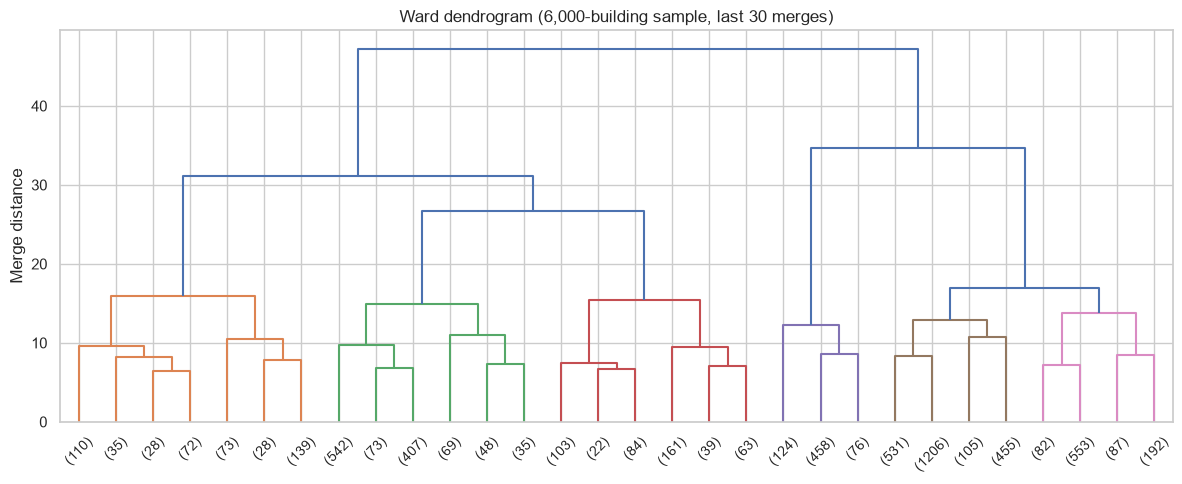

Largest merge distances: [47.2 34.7 31.1 26.7 16.9 16.  15.4 14.9]


In [14]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X), size=6000, replace=False)
X_sample = X[sample_idx]

Z = linkage(X_sample, method="ward")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=Z[-K + 1, 2])
ax.set_title("Ward dendrogram (6,000-building sample, last 30 merges)")
ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

print("Largest merge distances:", Z[-8:, 2].round(1)[::-1])

In [15]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_sample)
extend = KNeighborsClassifier(n_neighbors=5).fit(X_sample, ward.labels_)
labels_ward = extend.predict(X)

print(f"Ward silhouette: {silhouette_score(X, labels_ward, sample_size=6000, random_state=RANDOM_STATE):.3f}")
print(f"ARI K-Means vs Ward: {adjusted_rand_score(labels_kmeans, labels_ward):.3f}")
pd.crosstab(pd.Series(labels_kmeans, name="K-Means"), pd.Series(labels_ward, name="Ward"))

Ward silhouette: 0.237
ARI K-Means vs Ward: 0.591


Ward,0,1,2,3,4,5
K-Means,,,,,,
0,843,2,1,0,102,3
1,108,950,16,440,14,2
2,78,48,3,375,265,0
3,6,1,376,19,2,1486
4,117,237,5753,1469,86,3
5,29,25,3,59,2659,167


**Comparing the two algorithms.** The dendrogram has its largest jumps in the last few merges, so it supports a small number of
groups (4–6); we cut it at 6 to compare with K-Means. The two methods **partly agree (ARI ≈ 0.59)**:
- they find the **same curtain-wall group** (843 of 951 buildings) and the **same terra cotta group** (1,486 of 1,890);
- they disagree on the big brick mass: Ward splits the "solid load-bearing brick" group into two and mixes the cavity-wall and
  concrete-frame buildings differently.

K-Means has the better silhouette (0.38 vs 0.24 for Ward). Our features are shares between 0 and 1 and the groups are roughly
"blobs" around a typical facade, which is the shape K-Means assumes. K-Means can also assign **new buildings** with `.predict()`.
We keep **K-Means** as the final model and publish the Ward labels as an extra column (`cluster_ward`).

## 4. Stability

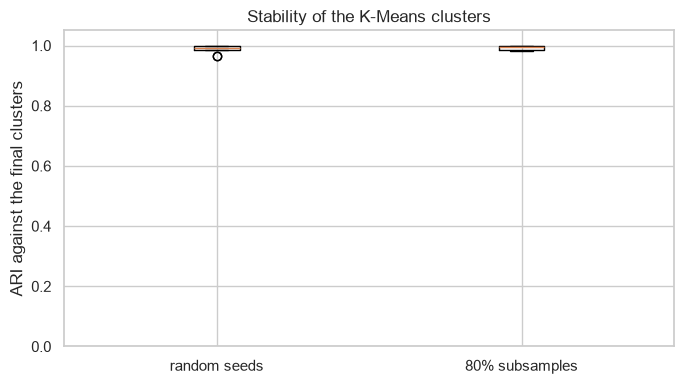

,check,mean ARI,min ARI
0,10 random seeds,0.988,0.965
1,10 subsamples of 80%,0.992,0.981


In [16]:
seed_ari = []
for seed in range(10):
    labels = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X)
    seed_ari.append(adjusted_rand_score(labels_kmeans, labels))

subsample_ari = []
for seed in range(10):
    idx = np.random.default_rng(seed).choice(len(X), size=int(0.8 * len(X)), replace=False)
    km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X[idx])
    subsample_ari.append(adjusted_rand_score(labels_kmeans, km.predict(X)))

stability = pd.DataFrame({
    "check": ["10 random seeds", "10 subsamples of 80%"],
    "mean ARI": [np.mean(seed_ari), np.mean(subsample_ari)],
    "min ARI": [np.min(seed_ari), np.min(subsample_ari)],
}).round(3)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([seed_ari, subsample_ari], tick_labels=["random seeds", "80% subsamples"])
ax.set_ylabel("ARI against the final clusters")
ax.set_ylim(0, 1.05)
ax.set_title("Stability of the K-Means clusters")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_stability.png", dpi=150, bbox_inches="tight")
plt.show()
stability

**Stability.** With 10 different seeds the clusters stay almost identical (mean ARI 0.99), and fitting on 10 random subsamples of 80%
of the buildings gives the same groups too (mean ARI 0.99, minimum 0.98). The K-Means clusters are **not an accident** of the seed or
of the sample. The weaker agreement with Ward (0.59) reminds us that a *different method* can still cut the brick mass differently.

## 5. Interpretation

### 5.1 Profiles of the clusters (features we clustered on)

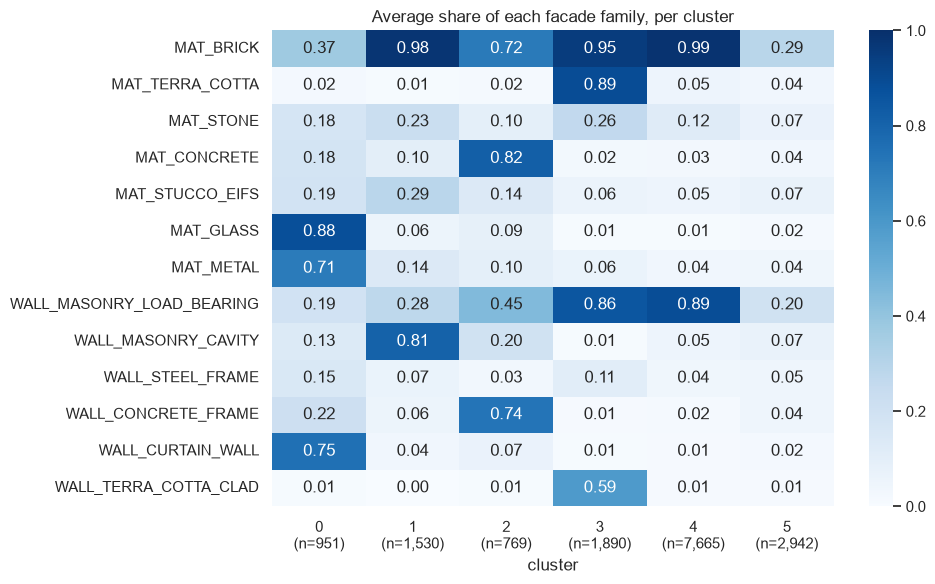

In [17]:
buildings["cluster"] = labels_kmeans
profile = buildings.groupby("cluster")[FEATURES].mean()
size = buildings["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(profile.T, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            xticklabels=[f"{c}\n(n={size[c]:,})" for c in profile.index])
ax.set_title("Average share of each facade family, per cluster")
ax.set_xlabel("cluster")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_cluster_profiles_raw.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Cross-tabulations with variables we did **not** cluster on

In [18]:
aside = buildings.groupby("cluster").agg(
    buildings=("BIN", "size"),
    share_pct=("BIN", lambda s: len(s) / len(buildings) * 100),
    other_material=("MAT_OTHER", "mean"),
    other_wall=("WALL_OTHER", "mean"),
    n_materials=("N_MATERIALS", "mean"),
    unsafe_share_of_reports=("SHARE_UNSAFE", "mean"),
    ever_unsafe=("EVER_UNSAFE", "mean"),
    median_penalty=("TOTAL_PENALTY_AMT", "median"),
    reports=("N_REPORTS", "mean"),
).round(2)
aside

,buildings,share_pct,other_material,other_wall,n_materials,unsafe_share_of_reports,ever_unsafe,median_penalty,reports
cluster,,,,,,,,,
0,951,6.04,0.25,0.28,2.58,0.10,0.19,4000.0,2.35
1,1530,9.72,0.14,0.13,1.83,0.17,0.29,10000.0,1.98
2,769,4.88,0.25,0.25,1.98,0.21,0.42,17800.0,3.20
3,1890,12.0,0.32,0.34,2.29,0.25,0.57,28000.0,3.73
4,7665,48.68,0.19,0.21,1.30,0.21,0.48,36000.0,3.57
5,2942,18.68,0.70,0.72,0.57,0.33,0.64,16000.0,3.43


In [19]:
borough_tab = pd.crosstab(buildings["cluster"], buildings["BOROUGH"], normalize="index").mul(100).round(0)
status_tab = pd.crosstab(buildings["cluster"], buildings["LATEST_STATUS"], normalize="index").mul(100).round(0)
display(borough_tab)
display(status_tab)

BOROUGH,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND
cluster,,,,,
0,2.0,13.0,75.0,9.0,0.0
1,19.0,33.0,34.0,14.0,0.0
2,7.0,19.0,61.0,11.0,1.0
3,7.0,4.0,88.0,1.0,0.0
4,15.0,12.0,55.0,17.0,1.0
5,17.0,20.0,47.0,13.0,2.0


LATEST_STATUS,SAFE,SWARMP,UNSAFE
cluster,,,
0,47.0,42.0,11.0
1,45.0,38.0,17.0
2,42.0,36.0,22.0
3,34.0,38.0,28.0
4,35.0,42.0,23.0
5,32.0,30.0,38.0


### 5.3 Naming the clusters

| Cluster | Name | Size | Why this name (clustered features) | What the other variables say (not clustered on) |
|---|---|---|---|---|
| 0 | **glass & metal curtain wall** | 951 (6%) | glass 0.88, metal 0.71, curtain wall 0.75; little brick (0.37) | 75% Manhattan; **lowest UNSAFE rate (10% of reports, 19% ever UNSAFE)**; the most materials per report (2.6) |
| 1 | **brick cavity wall** | 1,530 (10%) | brick 0.98 with cavity wall 0.81; the most stucco/EIFS (0.29) | the least Manhattan-centred group (34%; 33% Brooklyn, 19% Bronx); 17% UNSAFE; fewest reports (2.0): many joined the programme recently |
| 2 | **concrete frame** | 769 (5%) | concrete 0.82, concrete frame 0.74 | 61% Manhattan; 21% UNSAFE, close to the average |
| 3 | **terra cotta & brick (pre-war ornament)** | 1,890 (12%) | terra cotta 0.89 (cladding 0.59), brick 0.95, load-bearing 0.86, the most stone (0.26) | **88% Manhattan**; 25% UNSAFE, **57% ever UNSAFE** |
| 4 | **solid load-bearing brick** | 7,665 (49%) | brick 0.99, load-bearing masonry 0.89, almost nothing else (1.3 materials per report) | spread over all boroughs; 21% UNSAFE; highest median penalty ($36k) |
| 5 | **unspecified facade ("other")** | 2,942 (19%) | low on every family (brick only 0.29) | `MAT_OTHER` 0.70 and `WALL_OTHER` 0.72: the inspectors mostly wrote **"OTHER"**; **highest UNSAFE rate (33%, 64% ever UNSAFE, 38% UNSAFE at the latest report)** |

**Justification of the names**
- The names describe the **construction**, because that is what we clustered on; each one follows the highest values of the profile heatmap.
- *"pre-war ornament"* is **our domain knowledge**, not a column of the data: in New York, glazed terra cotta was used mostly before
  the Second World War, and 88% of these buildings are in Manhattan, where that stock is concentrated. The dataset has no construction year, so this is an interpretation.
- *"unspecified facade"* is a group defined by **missing information**, not by a material. It is still useful, and it is the one we
  find most interesting: these buildings are **UNSAFE far more often** (33% vs 23% overall). Either the "OTHER" facades really are
  harder to maintain, or the reports that describe the facade poorly come from buildings that are less well looked after. We can't
  tell which from this data.

**For the use case:** the DOB or a consultant could send terra cotta specialists to cluster 3, curtain-wall specialists to cluster 0,
and ask for a **better facade description** for the 2,942 "other" buildings, which also have the worst record.

In [20]:
# Our names, read from the profiles above. K-Means numbers can change with library versions, so each name is attached to the
# cluster whose centroid is highest on the defining feature (the names were checked against the tables above).
centroids = pd.DataFrame(kmeans_pipeline.named_steps["kmeans"].cluster_centers_, columns=FEATURES)
rules = [
    ("glass & metal curtain wall", centroids["WALL_CURTAIN_WALL"]),
    ("terra cotta & brick (pre-war ornament)", centroids["MAT_TERRA_COTTA"]),
    ("concrete frame", centroids["WALL_CONCRETE_FRAME"]),
    ("brick cavity wall", centroids["WALL_MASONRY_CAVITY"]),
    ("unspecified facade (\"other\")", -centroids.sum(axis=1)),
    ("solid load-bearing brick", centroids["WALL_MASONRY_LOAD_BEARING"]),
]
CLUSTER_NAMES = {}
for name, score in rules:
    candidates = score.drop(index=list(CLUSTER_NAMES))
    CLUSTER_NAMES[int(candidates.idxmax())] = name
CLUSTER_NAMES = dict(sorted(CLUSTER_NAMES.items()))
buildings["cluster_name"] = buildings["cluster"].map(CLUSTER_NAMES)
CLUSTER_NAMES

{0: 'glass & metal curtain wall',
 1: 'brick cavity wall',
 2: 'concrete frame',
 3: 'terra cotta & brick (pre-war ornament)',
 4: 'solid load-bearing brick',
 5: 'unspecified facade ("other")'}

In [21]:
summary = (
    buildings.groupby("cluster_name")
    .agg(cluster=("cluster", "first"), buildings=("BIN", "size"), share_pct=("BIN", lambda s: len(s) / len(buildings) * 100),
         manhattan_pct=("BOROUGH", lambda s: (s == "MANHATTAN").mean() * 100),
         unsafe_reports_pct=("SHARE_UNSAFE", lambda s: s.mean() * 100), ever_unsafe_pct=("EVER_UNSAFE", lambda s: s.mean() * 100))
    .sort_values("cluster").round(1)
)
summary

,cluster,buildings,share_pct,manhattan_pct,unsafe_reports_pct,ever_unsafe_pct
cluster_name,,,,,,
glass & metal curtain wall,0,951,6.0,75.4,10.2,19.3
brick cavity wall,1,1530,9.7,33.5,16.9,29.5
concrete frame,2,769,4.9,61.4,20.7,41.6
terra cotta & brick (pre-war ornament),3,1890,12.0,88.1,25.2,57.4
solid load-bearing brick,4,7665,48.7,55.3,21.3,48.3
"unspecified facade (""other"")",5,2942,18.7,46.7,33.4,63.7


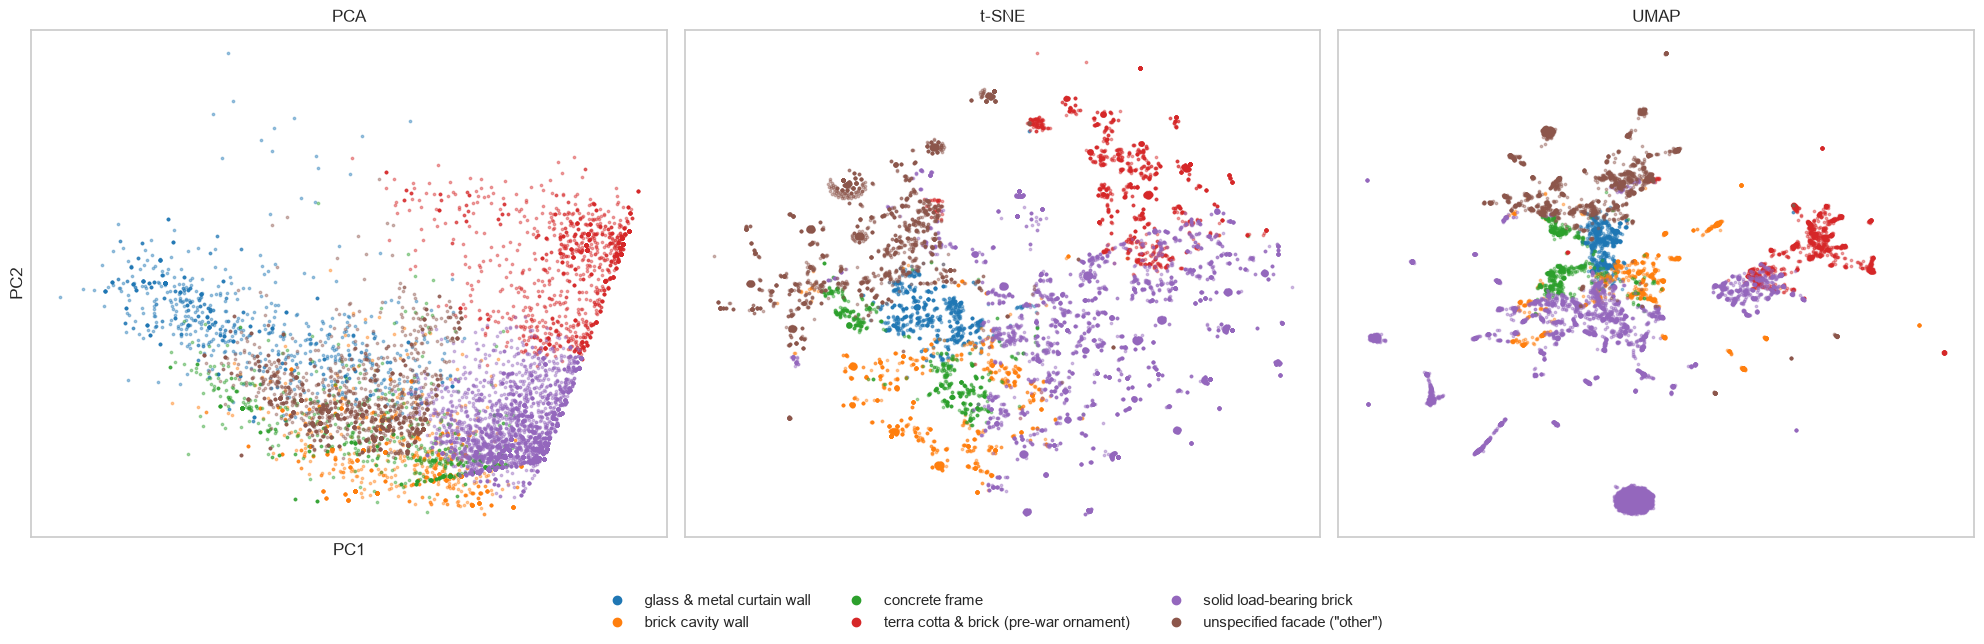

In [22]:
order = [CLUSTER_NAMES[c] for c in sorted(CLUSTER_NAMES)]
palette = dict(zip(order, sns.color_palette("tab10", len(order))))

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, coords, title in zip(axes, [pca_coordinates, tsne_coordinates, umap_coordinates], ["PCA", "t-SNE", "UMAP"]):
    for name in order:
        mask = (buildings["cluster_name"] == name).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=3, alpha=0.4, color=palette[name], label=name)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
handles = [plt.Line2D([], [], marker="o", linestyle="", color=palette[n], label=n) for n in order]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig(FIG_DIR / "09_clusters_on_maps.png", dpi=150, bbox_inches="tight")
plt.savefig(DATASET_DIR / "dataset_clusters_maps.png", dpi=120, bbox_inches="tight")
plt.show()

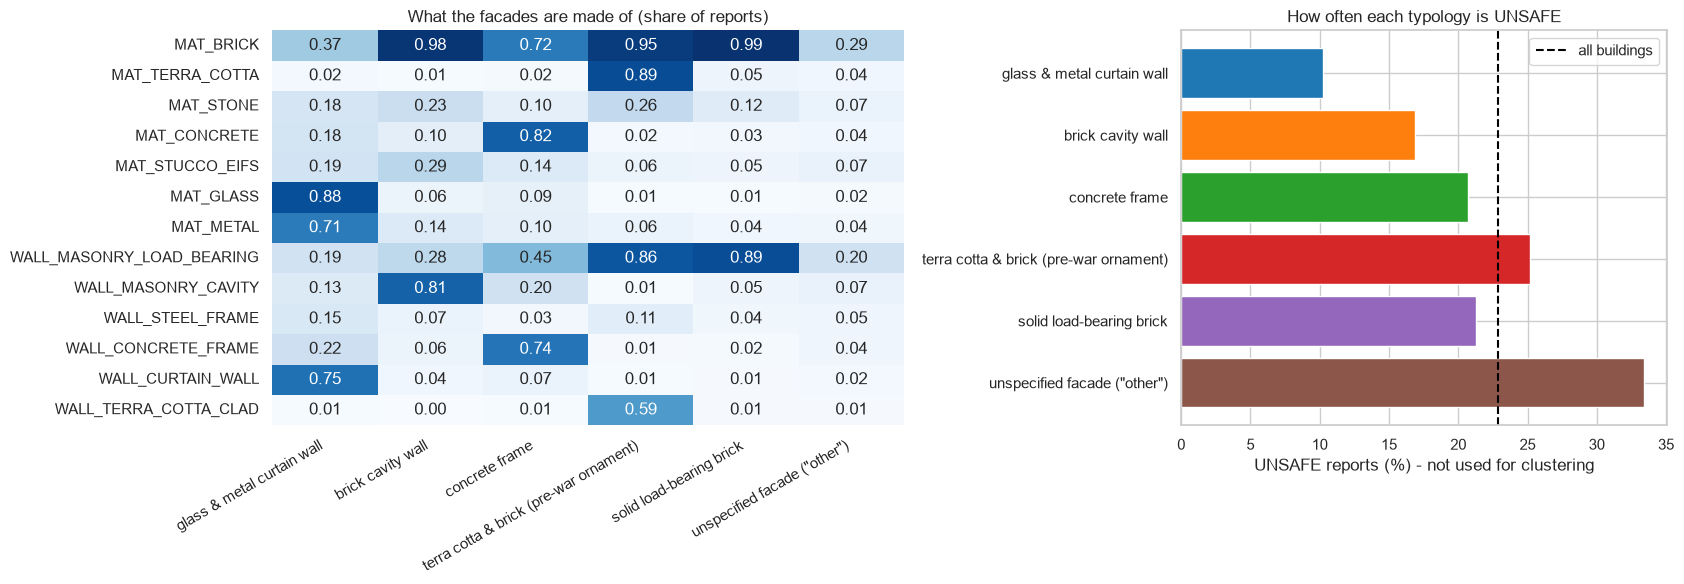

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.3, 1]})

named_profile = buildings.groupby("cluster_name")[FEATURES].mean().loc[order]
sns.heatmap(named_profile.T, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("What the facades are made of (share of reports)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
plt.setp(axes[0].get_xticklabels(), ha="right")

unsafe = (buildings.groupby("cluster_name")["SHARE_UNSAFE"].mean() * 100).loc[order]
axes[1].barh(order, unsafe, color=[palette[n] for n in order])
axes[1].axvline(buildings["SHARE_UNSAFE"].mean() * 100, color="black", linestyle="--", label="all buildings")
axes[1].invert_yaxis()
axes[1].set_xlabel("UNSAFE reports (%) - not used for clustering")
axes[1].set_title("How often each typology is UNSAFE")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "10_named_profiles_and_unsafe.png", dpi=150, bbox_inches="tight")
plt.savefig(DATASET_DIR / "dataset_cluster_profiles.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Save and reuse the model

We save the whole fitted pipeline (here: K-Means; no scaler needed) to `models/model.joblib`, reload it and assign a cluster to a
**hand-made building**. The input is one row with the 13 facade shares. For a single new report the shares are just 1 (mentioned)
or 0 (not mentioned).

In [24]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(kmeans_pipeline, model_path)
print(f"Saved {model_path} ({model_path.stat().st_size / 1e3:.0f} KB)")

model = joblib.load(model_path)
new_building = pd.DataFrame([dict.fromkeys(FEATURES, 0.0)])
new_building[["MAT_GLASS", "MAT_METAL", "WALL_CURTAIN_WALL", "WALL_STEEL_FRAME"]] = 1.0   # an office tower: glass and metal on steel
cluster = model.predict(new_building)[0]
print(f"New building -> cluster {cluster}: {CLUSTER_NAMES[cluster]}")

brownstone = pd.DataFrame([dict.fromkeys(FEATURES, 0.0)])
brownstone[["MAT_BRICK", "MAT_STONE", "WALL_MASONRY_LOAD_BEARING"]] = 1.0          # brick and stone, load-bearing
cluster = model.predict(brownstone)[0]
print(f"Brick-and-stone walk-up -> cluster {cluster}: {CLUSTER_NAMES[cluster]}")

Saved ..\models\model.joblib (65 KB)
New building -> cluster 0: glass & metal curtain wall
Brick-and-stone walk-up -> cluster 4: solid load-bearing brick


## 7. Export the clustered dataset

One row per building: the cleaned data, the engineered features, `cluster`, `cluster_name`, the Ward labels (`cluster_ward`, to show where the
two algorithms disagree) and the coordinates of the three maps.

In [25]:
final = buildings.copy()
final["cluster_ward"] = labels_ward
final[["pca_x", "pca_y"]] = pca_coordinates
final[["tsne_x", "tsne_y"]] = tsne_coordinates
final[["umap_x", "umap_y"]] = umap_coordinates

column_order = [
    "BIN", "BOROUGH", "BLOCK", "LOT", "HOUSE_NO", "STREET_NAME",
    "FIRST_CYCLE", "LAST_CYCLE", "N_REPORTS", "FIRST_FILING_YEAR", "LAST_FILING_YEAR",
    "EXTERIOR_WALL_TYPES_LATEST", "EXTERIOR_WALL_MATERIALS_LATEST",
    *FEATURES, "MAT_OTHER", "WALL_OTHER", "N_MATERIALS",
    "LATEST_STATUS", "N_UNSAFE", "N_SWARMP", "SHARE_UNSAFE", "EVER_UNSAFE", "TOTAL_PENALTY_AMT",
    "cluster", "cluster_name", "cluster_ward",
    "pca_x", "pca_y", "tsne_x", "tsne_y", "umap_x", "umap_y",
]
final = final[column_order]
float_columns = [*FEATURES, "MAT_OTHER", "WALL_OTHER", "N_MATERIALS", "SHARE_UNSAFE"]
final[float_columns] = final[float_columns].round(3)
final[["pca_x", "pca_y", "tsne_x", "tsne_y", "umap_x", "umap_y"]] = final[["pca_x", "pca_y", "tsne_x", "tsne_y", "umap_x", "umap_y"]].round(4)

dataset_path = DATASET_DIR / "nyc_facade_typologies.csv"
final.to_csv(dataset_path, index=False)
print(f"Saved {dataset_path}: {final.shape[0]:,} rows, {final.shape[1]} columns, {dataset_path.stat().st_size / 1e6:.1f} MB")
print("Missing values per column (only columns with any):")
print(final.isna().sum()[final.isna().sum() > 0])
final.head()

Saved ..\dataset\nyc_facade_typologies.csv: 15,747 rows, 44 columns, 4.3 MB
Missing values per column (only columns with any):
BLOCK                 4
TOTAL_PENALTY_AMT    44
dtype: int64


,BIN,BOROUGH,BLOCK,LOT,HOUSE_NO,STREET_NAME,FIRST_CYCLE,LAST_CYCLE,N_REPORTS,FIRST_FILING_YEAR,LAST_FILING_YEAR,EXTERIOR_WALL_TYPES_LATEST,EXTERIOR_WALL_MATERIALS_LATEST,MAT_BRICK,MAT_TERRA_COTTA,MAT_STONE,MAT_CONCRETE,MAT_STUCCO_EIFS,MAT_GLASS,MAT_METAL,WALL_MASONRY_LOAD_BEARING,WALL_MASONRY_CAVITY,WALL_STEEL_FRAME,WALL_CONCRETE_FRAME,WALL_CURTAIN_WALL,WALL_TERRA_COTTA_CLAD,MAT_OTHER,WALL_OTHER,N_MATERIALS,LATEST_STATUS,N_UNSAFE,N_SWARMP,SHARE_UNSAFE,EVER_UNSAFE,TOTAL_PENALTY_AMT,cluster,cluster_name,cluster_ward,pca_x,pca_y,tsne_x,tsne_y,umap_x,umap_y
0,1000005,MANHATTAN,4,7501,1,NEW YORK PLAZA,6,9,4,2006,2022,CURTAIN WALL; STEEL FRAME,GLASS; OTHER,0.00,0.75,0.0,0.0,0.0,1.00,0.0,0.0,0.00,0.25,0.0,1.00,0.75,1.00,0.75,1.75,SWARMP,0,4,0.0,0,0.0,0,glass & metal curtain wall,0,-0.9157,1.3190,-27.214001,-9.389100,-1.1965,12.7337
1,1000006,MANHATTAN,5,7501,117,BROAD STREET,6,9,4,2006,2022,OTHER; CURTAIN WALL; MASONRY CAVITY WALL,MASONRY; GLASS; OTHER,0.25,0.00,0.0,0.0,0.0,0.75,0.0,0.0,0.25,0.00,0.0,0.75,0.00,1.00,1.00,1.00,UNSAFE,2,0,0.5,1,80200.0,0,glass & metal curtain wall,0,-1.0148,0.2063,-20.472000,-8.948000,-1.3264,12.7855
2,1000007,MANHATTAN,5,10,113,BROAD STREET,6,10,5,2009,2026,MASONRY CAVITY WALL; STEEL FRAME; CURTAIN WALL,MASONRY; METAL; GLASS; STUCCO/EIFS; NATURAL STONE,1.00,0.00,0.2,0.2,0.2,0.20,0.2,0.6,0.20,0.40,0.0,0.40,0.00,0.00,0.20,2.00,SAFE,1,2,0.2,1,256250.0,4,solid load-bearing brick,2,-0.1206,-0.0380,-1.571000,-23.570801,-1.2173,8.2682
3,1000016,MANHATTAN,8,44,102,BROAD STREET,6,9,4,2007,2022,MASONRY LOAD-BEARING WALL,OTHER; MASONRY,1.00,0.00,0.0,0.0,0.0,0.00,0.0,1.0,0.00,0.00,0.0,0.00,0.00,1.00,0.75,1.00,SAFE,2,0,0.5,1,151000.0,4,solid load-bearing brick,2,0.3929,-0.2554,1.492700,38.605598,0.4976,-4.1431
4,1000018,MANHATTAN,9,1,1,STATE STREET PLAZA,6,9,4,2007,2023,CURTAIN WALL; STEEL FRAME,GLASS; METAL; MASONRY,0.25,0.00,0.0,0.0,0.0,1.00,1.0,0.0,0.00,0.25,0.0,1.00,0.00,0.75,0.75,2.25,SWARMP,0,3,0.0,0,83400.0,0,glass & metal curtain wall,0,-1.3078,0.6153,-31.314100,-7.998200,-0.4062,12.5386


## 8. Conclusions

**Key findings**
- New York's tall buildings (15,747 with a facade description) fall into **6 facade typologies**; K-Means with k = 6 has the best silhouette (0.38) and is very stable (ARI 0.99 over seeds and 80% subsamples).
- **Half of the buildings (49%) are plain solid load-bearing brick.** The other typologies are minorities: terra cotta & brick (12%), brick cavity wall (10%), glass & metal curtain wall (6%), concrete frame (5%).
- **The typologies differ in risk**, although the UNSAFE history was never given to the algorithm: curtain walls are UNSAFE in 10% of reports, terra cotta buildings in 25%.
- **19% of buildings are described only as "OTHER"**, and this group has the worst record (33% UNSAFE, 64% ever UNSAFE).
- Terra cotta (88%) and curtain-wall (75%) buildings are mostly in **Manhattan**; cavity-wall buildings are the most spread out (Brooklyn, Bronx).

**Limitations and biases**
- **Self-reported descriptions.** The facade families come from what inspectors ticked in their reports, not from a survey. The same building can be described differently in different cycles (we used shares to soften this).
- **No age, height or size** in the data: "pre-war" is our interpretation, not a fact in the data.
- **Moderate separation** (silhouette 0.38) and only partial agreement with Ward (ARI 0.59): the borders between the brick groups are a choice, not a law of nature.
- **Coverage:** only NYC buildings taller than 6 stories in the FISP programme, cycles 6–10.
- **Not for:** predicting whether a specific facade is safe (that needs an inspection), or for buildings outside NYC or below 7 stories.